## 01 / Источники и диагностика
Синтетическая сеть, 2024–2025. Hoff — отраслевой референс. Все суммы в рублях без НДС.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
R=Path.cwd(); O=R/'data/processed'; D=R/'data/raw'
def read(name): return pd.read_csv(O/f'{name}.csv')
def raw(name): return pd.read_csv(D/f'{name}.csv')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=['#14243D','#BBA17A','#64748B'])})
pd.DataFrame([(p.name,len(pd.read_csv(p))) for p in sorted(D.glob('*.csv'))],columns=['table','rows'])

,table,rows
0,calendar.csv,731
1,categories.csv,6
2,customers.csv,18000
3,deliveries.csv,68752
4,inventory.csv,43200
5,marketing_channels.csv,4
6,order_items.csv,101911
7,orders.csv,72000
8,products.csv,600
9,promotions.csv,4


## 02 / Очистка и связи
Удаляем только полные дубли; пропуски цены восстанавливаем из справочника согласно генератору.

In [2]:
i=raw('order_items'); p=raw('products'); o=raw('orders'); r=raw('returns')
print('Дубли:',i.duplicated().sum(),'Пропуски:',i.unit_price.isna().sum())
i=i.drop_duplicates().merge(p[['product_id','list_price']],on='product_id',validate='many_to_one'); i.unit_price=i.unit_price.fillna(i.list_price); i=i.drop(columns='list_price')
assert i.item_id.is_unique and o.order_id.is_unique and r.return_id.is_unique
assert set(i.order_id)<=set(o.order_id) and set(r.item_id)<=set(i.item_id)
assert np.allclose(i.sort_values('item_id').unit_price,read('order_items').sort_values('item_id').unit_price)
f=read('sales_fact'); assert f.item_id.is_unique and f.returned.le(f.quantity).all()
assert np.allclose(f.net-f.cogs,f.profit)
assert np.allclose(f.net,np.floor((f.quantity-f.returned)*f.unit_price*(1-f.discount)*100+0.50000001)/100)
f.head(3)

Дубли: 80 Пропуски: 30


,item_id,order_id,product_id,promotion_id,quantity,unit_price,unit_cost,day,customer_id,store_id,warehouse_id,channel,marketing_id,status,category_id,category,discount,region,returned,gross,net,cogs,profit,year,month
0,1,1,164,2,1,21004.13,11972.35,2024-01-01,4642,4,2,store,4,completed,2,Кровати,0.1,Казань,0,21004.13,18903.72,11972.35,6931.37,2024,2024-01
1,2,2,96,1,1,27117.33,15999.22,2024-01-01,7553,1,1,store,3,completed,1,Диваны,0.0,Москва,0,27117.33,27117.33,15999.22,11118.11,2024,2024-01
2,3,3,446,2,1,1312.01,564.16,2024-01-01,15215,2,1,store,4,completed,5,Текстиль,0.1,Москва,0,1312.01,1180.81,564.16,616.65,2024,2024-01


## 03 / Финансовая динамика
Маржа — отношение сумм, заказы — уникальные идентификаторы. Возвраты относятся к когорте продажи.

,net,cogs,profit,orders,units,returned,margin,aov,return_rate
year,,,,,,,,,
2024,1.213716e+09,7.996120e+08,4.141045e+08,31409,58651,2724,0.341187,38642.315139,0.046444
2025,1.478053e+09,1.105845e+09,3.722079e+08,37343,68909,3690,0.251823,39580.449514,0.053549


net            0.217791
cogs           0.382977
profit        -0.101174
orders         0.188927
units          0.174899
returned       0.354626
margin        -0.261921
aov            0.024277
return_rate    0.152972
Name: YoY, dtype: float64

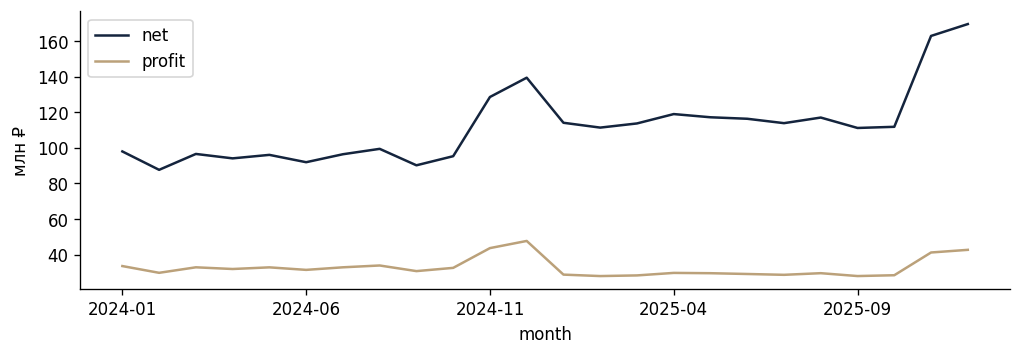

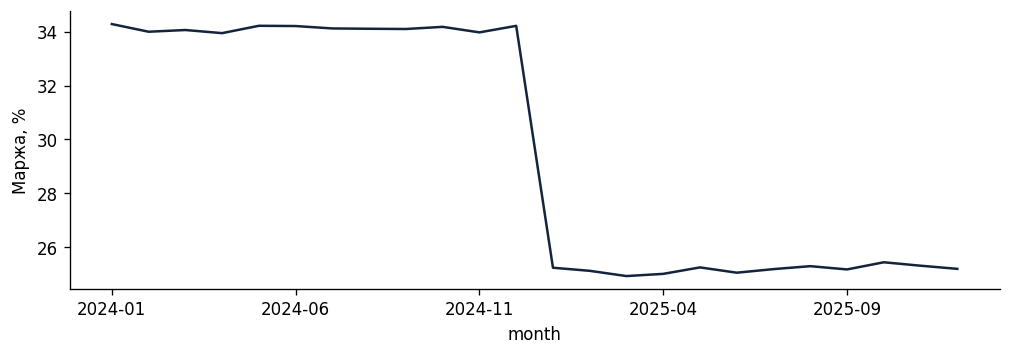

In [3]:
a=f.groupby('year').agg(net=('net','sum'),cogs=('cogs','sum'),profit=('profit','sum'),orders=('order_id','nunique'),units=('quantity','sum'),returned=('returned','sum'))
a['margin']=a.profit/a.net; a['aov']=a.net/a.orders; a['return_rate']=a.returned/a.units
display(a); display(a.pct_change().iloc[-1].rename('YoY'))
m=f.groupby('month')[['net','profit']].sum(); m['margin']=m.profit/m.net
m[['net','profit']].div(1e6).plot(figsize=(10,3),ylabel='млн ₽'); plt.show()
m.margin.mul(100).plot(figsize=(10,3),ylabel='Маржа, %'); plt.show()

## 04 / Факторный мост
Цепные подстановки: объём, микс категорий, цена, скидка, себестоимость, возвраты. Взаимодействия зависят от порядка; среднее по 720 порядкам — Шепли.

,factor,effect
0,Объём,7.242646e+07
1,Микс категорий,3.534013e+07
2,Цена до скидки,-2.946619e+06
3,Скидки,-1.059710e+08
4,Себестоимость,-4.919702e+07
5,Возвраты,8.451440e+06
6,Округление,3.065000e+00


,factor,min,max,shapley,positive_orders
0,Объём,5.144941e+07,7.894540e+07,6.430364e+07,720
1,Микс категорий,1.544013e+07,3.696482e+07,2.530871e+07,720
2,Цена до скидки,-2.946619e+06,-2.153212e+06,-2.539574e+06,0
3,Скидки,-1.059710e+08,-8.091706e+07,-9.317356e+07,0
4,Себестоимость,-4.919702e+07,-3.686780e+07,-4.288649e+07,0
5,Возвраты,5.810496e+06,8.451440e+06,7.090658e+06,720


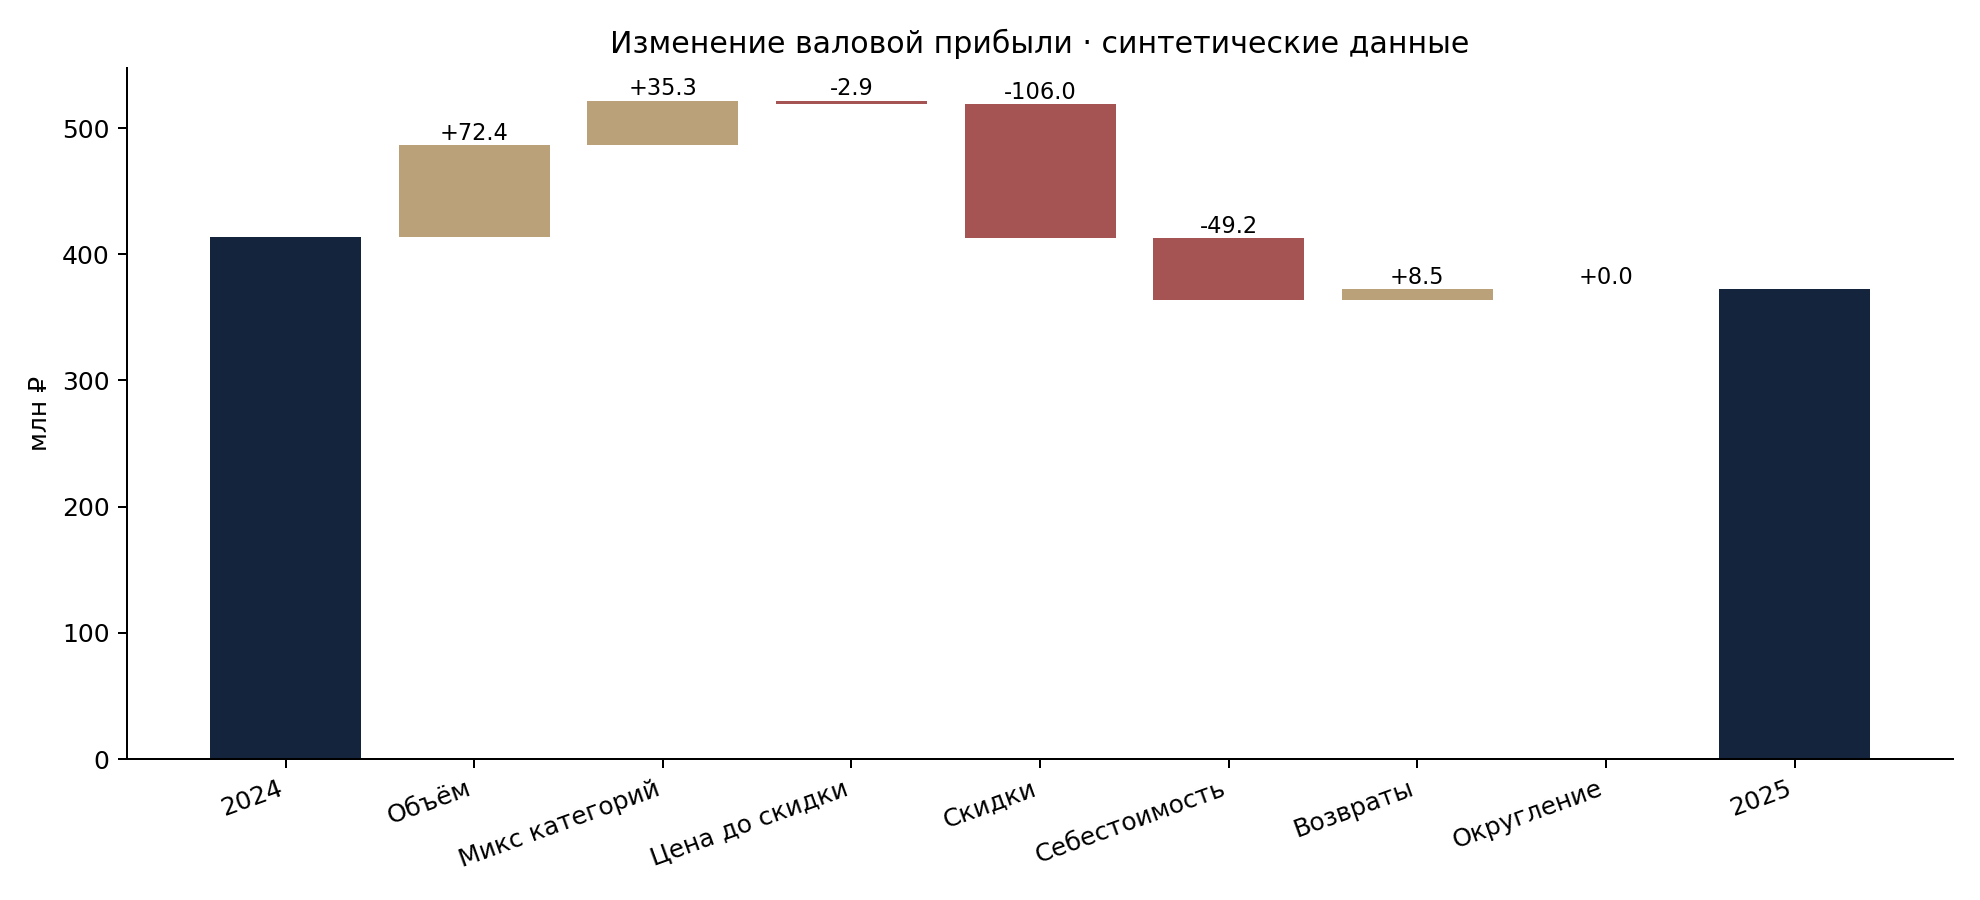

,category,return_profit_per_unit_2024,return_profit_per_unit_2025,effect
0,Диваны,745.572095,552.038098,2.031720e+06
1,Кровати,497.287738,425.058827,6.098287e+05
2,Кухни,1467.632893,981.797838,4.859322e+06
3,Освещение,98.812500,102.221736,-3.613109e+04
4,Текстиль,39.661167,38.554451,2.360624e+04
5,Шкафы,574.674665,454.857015,9.630943e+05


In [4]:
b=read('profit_bridge'); s=read('factor_sensitivity'); assert abs(a.profit.diff().iloc[-1]-b.effect.sum())<.01
display(b); display(s); display(Image(filename=str(R/'images/profit_waterfall.png')))
display(read('return_factor_detail'))

## 05 / Скидки и себестоимость
H1: глубокие скидки связаны с меньшей маржой. Сравнение внутри категории и года снижает смешение, но не измеряет эластичность.

In [5]:
d=f.groupby(['year','category','discount'])[['net','profit']].sum(); d['margin']=d.profit/d.net
pivot=d.margin.unstack('discount'); display(pivot)
print('Доля групп, где маржа при максимальной скидке ниже нулевой:',(pivot.iloc[:,-1]<pivot.iloc[:,0]).mean())
f['cost_ratio']=f.unit_cost/f.unit_price
f.groupby('year').cost_ratio.mean().to_frame('mean_line_cost_ratio')

discount            0.0       0.1       0.2       0.3
year category                                        
2024 Диваны     0.41000  0.344444  0.262500  0.157143
     Кровати    0.43000  0.366667  0.287500  0.185714
     Кухни      0.33000  0.255556  0.162500  0.042857
     Освещение  0.52000  0.466667  0.400000  0.314286
     Текстиль   0.57000  0.522222  0.462500  0.385714
     Шкафы      0.40000  0.333333  0.250000  0.142857
2025 Диваны     0.38345  0.314944  0.229313  0.119214
     Кровати    0.40435  0.338167  0.255438  0.149071
     Кухни      0.29985  0.222056  0.124812 -0.000214
     Освещение  0.49840  0.442667  0.373000  0.283429
     Текстиль   0.55065  0.500722  0.438312  0.358071
     Шкафы      0.37300  0.303333  0.216250  0.104286

Доля групп, где маржа при максимальной скидке ниже нулевой: 1.0


,mean_line_cost_ratio
year,
2024,0.551087
2025,0.585834


## 06 / Ассортимент
H2: смещение микса в менее маржинальные категории ухудшает прибыльность. Проверяем знак эффекта микса, а не только рейтинг выручки.

net        profit  ...  return_rate  unit_share
year category                               ...                         
2024 Диваны     3.527167e+08  1.237996e+08  ...     0.051877    0.152171
     Кровати    2.156938e+08  8.073875e+07  ...     0.048644    0.143356
     Кухни      3.157659e+08  8.318575e+07  ...     0.087505    0.090604
     Освещение  5.153585e+07  2.434543e+07  ...     0.034597    0.149818
     Текстиль   3.958517e+07  2.088923e+07  ...     0.036269    0.335646
     Шкафы      2.384191e+08  8.114576e+07  ...     0.048997    0.128404
2025 Диваны     3.880852e+08  1.072012e+08  ...     0.054106    0.152346
     Кровати    2.012675e+08  6.085622e+07  ...     0.054838    0.122524
     Кухни      5.543485e+08  9.911698e+07  ...     0.088882    0.145148
     Освещение  5.802430e+07  2.384336e+07  ...     0.041045    0.153797
     Текстиль   3.992217e+07  1.883085e+07  ...     0.041866    0.309539
     Шкафы      2.364051e+08  6.235925e+07  ...     0.054989    0.116647

[12 rows x 7 columns]

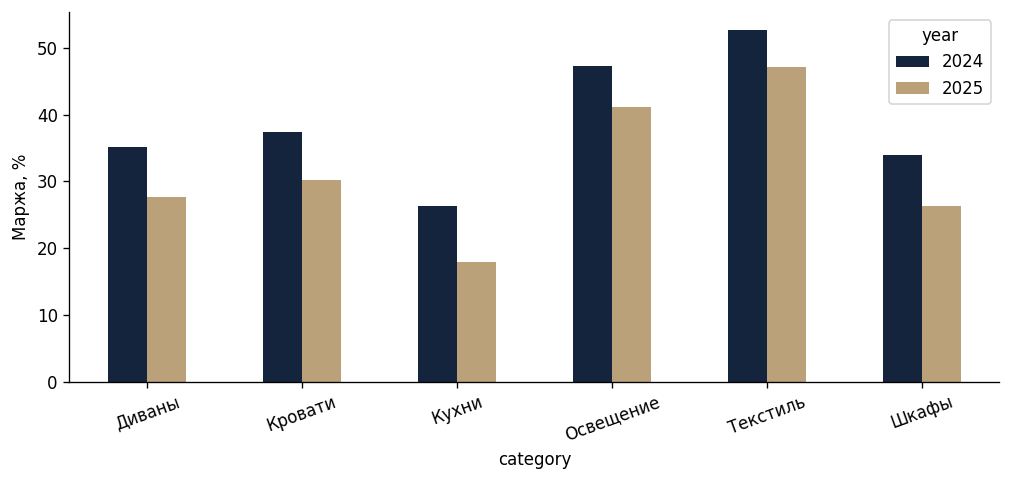

Эффект микса: 35340129.86876649


In [6]:
c=f.groupby(['year','category'])[['net','profit','quantity','returned']].sum(); c['margin']=c.profit/c.net; c['return_rate']=c.returned/c.quantity
c['unit_share']=c.quantity/c.groupby(level=0).quantity.transform('sum'); display(c)
c.margin.unstack(0).mul(100).plot.bar(figsize=(10,4),ylabel='Маржа, %'); plt.xticks(rotation=20); plt.show()
print('Эффект микса:',b.iloc[1].effect)

## 07 / Возвраты
H4: возвраты концентрируются в отдельных категориях. Положительный эффект в мосте означает изменение удельной потерянной прибыли, а не пользу возвратов.

units  returned  lost_profit      rate
year category                                         
2024 Диваны      8925       463  6654230.947  0.051877
     Кровати     8408       409  4181195.297  0.048644
     Кухни       5314       465  7799001.196  0.087505
     Освещение   8787       304   868265.434  0.034597
     Текстиль   19686       714   780769.728  0.036269
     Шкафы       7531       369  4327874.899  0.048997
2025 Диваны     10498       568  5795295.954  0.054106
     Кровати     8443       463  3588771.679  0.054838
     Кухни      10002       889  9819941.978  0.088882
     Освещение  10598       435  1083345.960  0.041045
     Текстиль   21330       893   822366.443  0.041866
     Шкафы       8038       442  3656140.689  0.054989

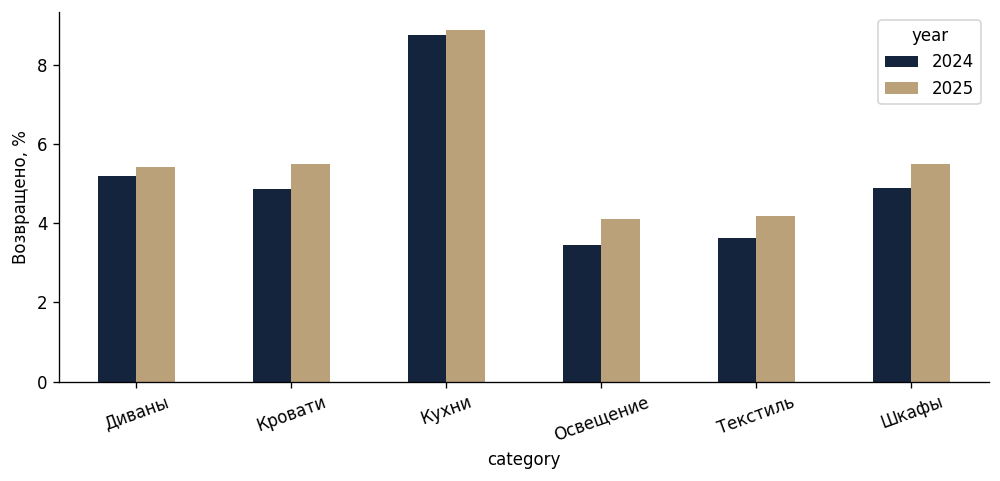

In [7]:
f['lost_profit']=f.returned*(f.unit_price*(1-f.discount)-f.unit_cost)
ret=f.groupby(['year','category']).agg(units=('quantity','sum'),returned=('returned','sum'),lost_profit=('lost_profit','sum')); ret['rate']=ret.returned/ret.units; display(ret)
ret.rate.unstack(0).mul(100).plot.bar(figsize=(10,4),ylabel='Возвращено, %'); plt.xticks(rotation=20); plt.show()

## 08 / Клиенты
Сегменты по наблюдаемой частоте и давности; это не прогноз CLV. Когорты ограничены окном наблюдения.

,buyers,net
segment,,
active_repeat,4775,1.557930e+09
one_time,3253,1.289119e+08
other,7427,1.004927e+09


,buyers,repeat_buyers,repeat_rate
year,,,
2024,12209,7341,0.601278
2025,13076,8477,0.648287


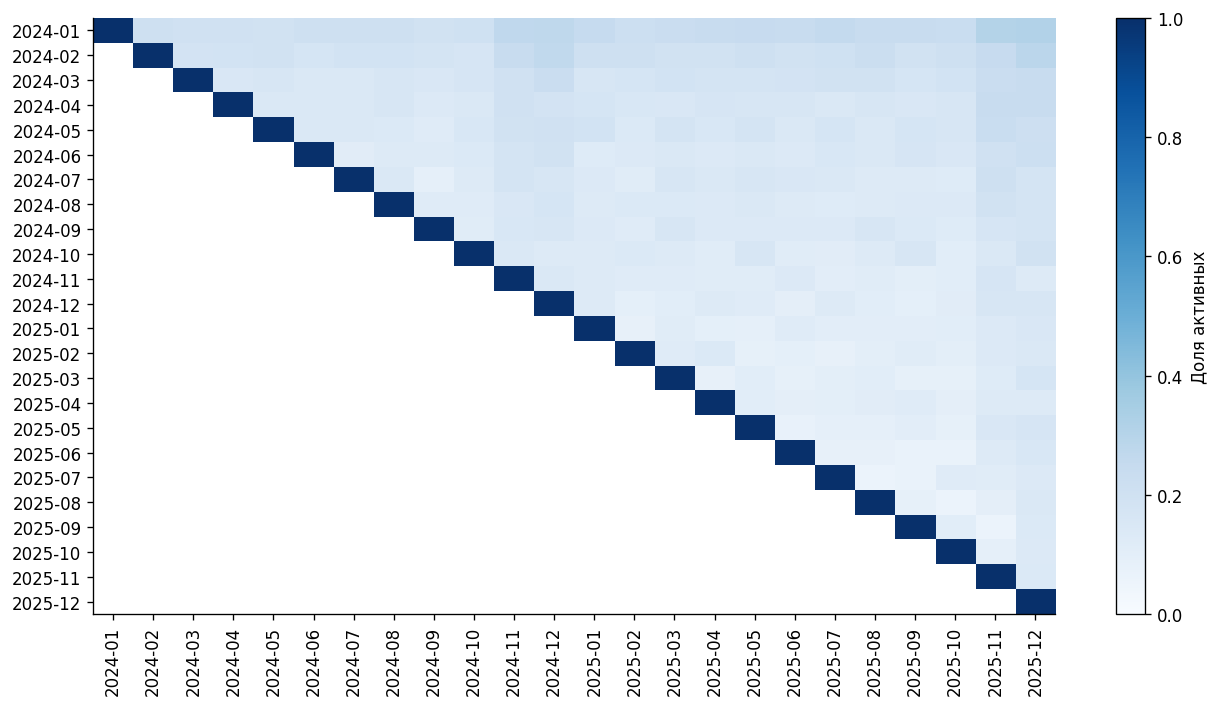

In [8]:
cust=f.groupby('customer_id').agg(last=('day','max'),frequency=('order_id','nunique'),monetary=('net','sum')); cust['recency']=(pd.Timestamp('2026-01-01')-pd.to_datetime(cust['last'])).dt.days
cust['segment']=np.select([(cust.frequency>=4)&(cust.recency<=90),cust.frequency==1],['active_repeat','one_time'],default='other')
seg=cust.groupby('segment').agg(buyers=('frequency','size'),net=('monetary','sum')); display(seg)
cy=f.groupby(['year','customer_id']).order_id.nunique().rename('n').reset_index(); rep=cy.assign(repeat=cy.n>1).groupby('year').agg(buyers=('n','size'),repeat_buyers=('repeat','sum'),repeat_rate=('repeat','mean')); display(rep)
act=f[['customer_id','month']].drop_duplicates(); act['cohort']=act.groupby('customer_id').month.transform('min'); cohort=act.groupby(['cohort','month']).size().rename('active').reset_index(); cohort['cohort_size']=cohort.groupby('cohort').active.transform('first'); cohort['retention']=cohort.active/cohort.cohort_size
heat=cohort.pivot(index='cohort',columns='month',values='retention'); fig,ax=plt.subplots(figsize=(11,6)); im=ax.imshow(heat,aspect='auto',vmin=0,vmax=1,cmap='Blues'); ax.set_xticks(range(len(heat.columns)),heat.columns,rotation=90); ax.set_yticks(range(len(heat.index)),heat.index); fig.colorbar(im,ax=ax,label='Доля активных'); plt.tight_layout(); plt.show()

## 09 / Запасы
H5: сезонный спрос и неоднородность SKU создают риск дефицита и избытка. Остатки условны на продажах; срочное пополнение бесплатно в модели, возвраты пригодны к продаже.

,value_days,shortage,exposure,unmet,units,avg_inventory,turnover,dio,stockout_rate,unmet_rate
year,,,,,,,,,,
2024,9.393061e+10,2568,658800,132,58651,2.566410e+08,3.115683,117.470240,0.003898,0.002246
2025,1.047461e+11,2294,657000,118,68909,2.869757e+08,3.853444,94.720454,0.003492,0.001709


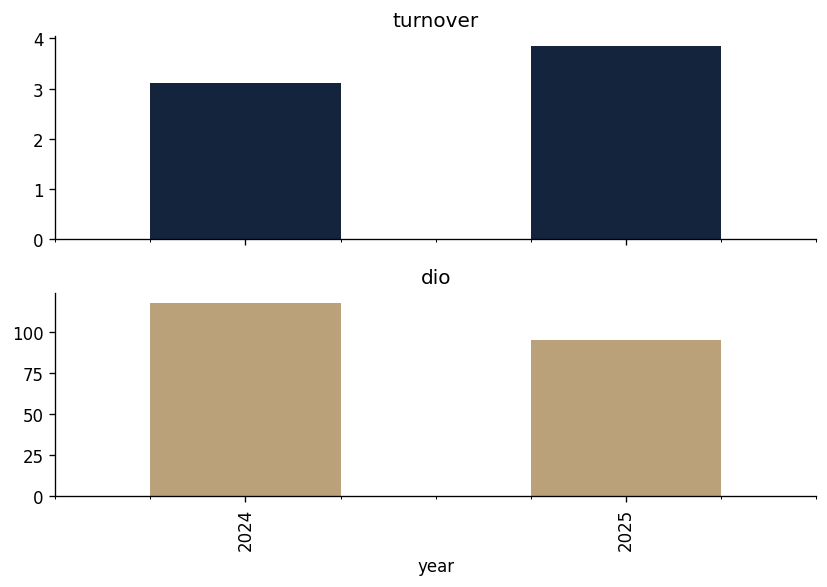

,sales,stockout_days,unmet_demand
sales,1.000000,-0.113043,0.283783
stockout_days,-0.113043,1.000000,0.349272
unmet_demand,0.283783,0.349272,1.000000


SKU-склад-месяцы с запасом и без продаж: 5599


xyz        X    Y   Z
year abc             
2024 A    10  239  53
     B     5   90  44
     C     4   89  66
2025 A    19  241  20
     B     5  121  21
     C     6  127  40

In [9]:
inv=raw('inventory').merge(p,on='product_id',validate='many_to_one'); inv['year']=inv.month.str[:4].astype(int); inv['days']=pd.to_datetime(inv.month).dt.days_in_month; inv['value_days']=inv.stock_unit_days*inv.unit_cost*np.where(inv.year==2025,1.045,1)
assert (inv.stock_start+inv.receipts+inv.emergency_receipts+inv.restocked-inv.sales==inv.stock_end).all()
stock=inv.groupby('year').agg(value_days=('value_days','sum'),shortage=('stockout_days','sum'),exposure=('days','sum'),unmet=('unmet_demand','sum'),units=('sales','sum')); stock['avg_inventory']=stock.value_days/pd.Series({2024:366,2025:365}); stock['turnover']=a.cogs/stock.avg_inventory; stock['dio']=stock.value_days/a.cogs; stock['stockout_rate']=stock.shortage/stock.exposure; stock['unmet_rate']=stock.unmet/(stock.units+stock.unmet); display(stock)
stock[['turnover','dio']].plot.bar(subplots=True,figsize=(7,5),legend=False); plt.tight_layout(); plt.show()
monthly=inv.groupby('month')[['sales','stockout_days','unmet_demand']].sum(); display(monthly.corr(method='spearman'))
print('SKU-склад-месяцы с запасом и без продаж:',((inv.stock_end>0)&(inv.sales==0)).sum())
abc=read('abc_xyz'); display(pd.crosstab([abc.year,abc.abc],abc.xyz))

## 10 / Каналы и логистика
H3: рост онлайн-доли увеличивает общие расходы доставки. Расходы считаются на заказ, отдельно от валовой прибыли.

orders      cost  cost_per_order  late_rate
year channel                                             
2024 online    10117  15714588     1553.285361   0.168232
     store     21292   5316114      249.676592   0.082331
2025 online    16961  26296515     1550.410648   0.169565
     store     20382   5097548      250.100481   0.081592

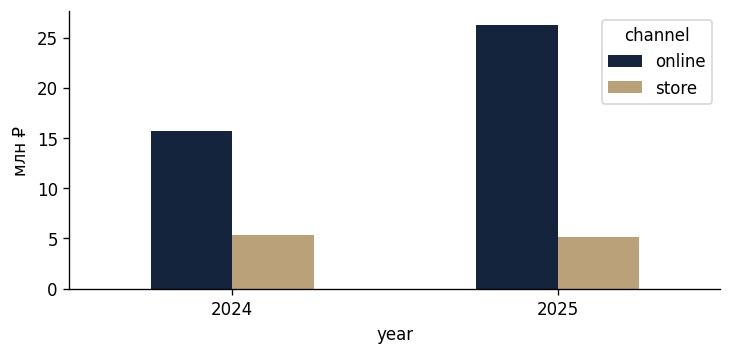

Доля онлайн: year
2024    0.322105
2025    0.454195
dtype: float64


In [10]:
delivery=raw('deliveries').merge(o,on='order_id',validate='one_to_one'); delivery=delivery[delivery.status=='completed'].copy(); delivery['year']=delivery.day.str[:4].astype(int); delivery['late']=delivery.actual_days>delivery.promised_days
log=delivery.groupby(['year','channel']).agg(orders=('order_id','size'),cost=('delivery_cost','sum'),cost_per_order=('delivery_cost','mean'),late_rate=('late','mean')); display(log)
log.cost.unstack().div(1e6).plot.bar(figsize=(7,3),ylabel='млн ₽'); plt.xticks(rotation=0); plt.show()
print('Доля онлайн:',log.orders.unstack().online/log.orders.groupby(level=0).sum())

## 11 / Управленческий парадокс
Оборачиваемость = COGS / средний запас. DIO = дни / оборачиваемость. Рост COGS может одновременно ускорять оборот и снижать маржу. GMROI показывает валовую прибыль на рубль среднего запаса.

,COGS,avg_inventory,gross_profit,GMROI
year,,,,
2024,7.996120e+08,2.566410e+08,4.141045e+08,1.613556
2025,1.105845e+09,2.869757e+08,3.722079e+08,1.297002


COGS             0.382977
avg_inventory    0.118199
gross_profit    -0.101174
GMROI           -0.196184
Name: 2025, dtype: float64

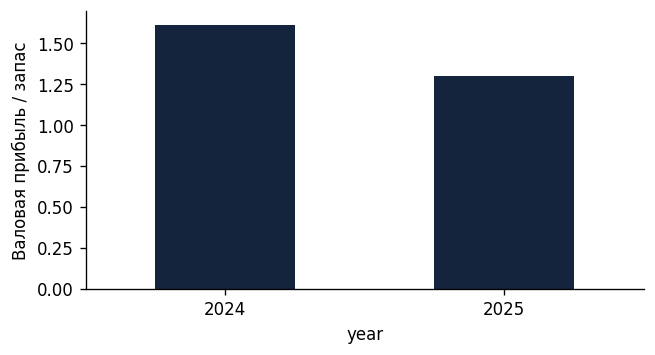

In [11]:
par=pd.DataFrame({'COGS':a.cogs,'avg_inventory':stock.avg_inventory,'gross_profit':a.profit,'GMROI':a.profit/stock.avg_inventory}); display(par); display(par.pct_change().iloc[-1])
par.GMROI.plot.bar(figsize=(6,3),ylabel='Валовая прибыль / запас'); plt.xticks(rotation=0); plt.show()

## 12 / Независимая сверка SQL и Python
Сравниваем ключи и значения, а не только число строк.

In [12]:
def compare(left,right,keys,cols):
 x=left.reset_index().merge(right,on=keys,validate='one_to_one',suffixes=('_py','_sql'),how='outer',indicator=True); assert x._merge.eq('both').all()
 for col in cols: assert np.allclose(x[col+'_py'],x[col+'_sql'],rtol=1e-9,atol=.01),col
compare(a,read('sql_01'),['year'],['net','profit','orders'])
compare(stock,read('sql_22'),['year'],['avg_inventory','turnover','dio','stockout_rate','unmet_rate'])
compare(rep,read('sql_25'),['year'],['buyers','repeat_buyers','repeat_rate'])
compare(seg,read('sql_26'),['segment'],['buyers','net'])
compare(cohort,read('sql_24'),['cohort','month'],['active','cohort_size','retention'])
compare(log,read('sql_29'),['year','channel'],['orders','cost','cost_per_order','late_rate'])
z=abc.merge(read('sql_23'),on=['year','product_id'],validate='one_to_one',suffixes=('_py','_sql')); assert len(z)==len(abc)==1200 and z.abc_py.eq(z.abc_sql).all() and z.xyz_py.eq(z.xyz_sql).all()
assert read('sql_28')[['balance_errors','continuity_errors']].eq(0).all().all()
print('8 сверок пройдены')

8 сверок пройдены


## 13 / Проверка гипотез и решения
Описательная проверка, без формальных p-value: зависимости заданы генератором, наблюдения не являются независимым экспериментом.

In [13]:
h=pd.DataFrame([['H1','Поддержана',f'{(pivot.iloc[:,-1]<pivot.iloc[:,0]).mean():.0%} групп: маржа ниже при максимальной скидке','Пилот ограничения скидок; контролировать прибыль и объём'],['H2','Не поддержана',f'Эффект микса {b.iloc[1].effect/1e6:+.2f} млн ₽','Не сокращать категории только по низкой марже'],['H3','Поддержана',f'Расходы доставки +{log.cost.groupby(level=0).sum().pct_change().iloc[-1]:.1%}','Контроль затрат на заказ и SLA'],['H4','Поддержана',f'Максимальная доля возвратов 2025: {ret.loc[2025].rate.max():.2%}','Проверка комплектации и причин возврата'],['H5','Частично поддержана',f'Запас без продаж: {((inv.stock_end>0)&(inv.sales==0)).sum()} SKU-склад-месяцев; дефицит {stock.stockout_rate.iloc[-1]:.3%}','Пилот пополнения по ABC/XYZ; проверить фактический спрос']],columns=['hypothesis','status','evidence','action']); display(h); h.to_csv(O/'hypotheses_stage3.csv',index=False)
par.to_csv(O/'inventory_profit_paradox.csv'); seg.to_csv(O/'customer_segments_stage3.csv'); rep.to_csv(O/'repeat_annual.csv'); cohort.to_csv(O/'cohort_retention.csv',index=False)

,hypothesis,status,evidence,action
0,H1,Поддержана,100% групп: маржа ниже при максимальной скидке,Пилот ограничения скидок; контролировать прибы...
1,H2,Не поддержана,Эффект микса +35.34 млн ₽,Не сокращать категории только по низкой марже
2,H3,Поддержана,Расходы доставки +49.3%,Контроль затрат на заказ и SLA
3,H4,Поддержана,Максимальная доля возвратов 2025: 8.89%,Проверка комплектации и причин возврата
4,H5,Частично поддержана,Запас без продаж: 5599 SKU-склад-месяцев; дефи...,Пилот пополнения по ABC/XYZ; проверить фактиче...
